# Exploração do Dataset CWRU e Geração de Escalogramas via CWT

**Projeto:** Diagnóstico de Falhas em Rolamentos via CNN + Transformada Wavelet Contínua  
**Dataset:** Case Western Reserve University (CWRU) Bearing Data  
**Objetivo:** Explorar os sinais de vibração do dataset CWRU, gerar escalogramas por meio da
Transformada Wavelet Contínua (CWT) e preparar imagens para a Rede Neural Convolucional (CNN).

---

## 1. Importação de Módulos e Parâmetros do Projeto

Importamos as bibliotecas e as configurações centrais diretamente do pacote `src` do projeto,
garantindo que qualquer alteração em `src/config.py` seja refletida automaticamente aqui.

In [1]:
import sys
from pathlib import Path

# Adicionar a raiz do projeto ao sys.path para importar os módulos da pasta src
BASE_DIR = Path.cwd().parent.parent if Path.cwd().name in ['1_cwru', '2_paderborn', '3_xjtu', '4_cross_domain_tempo', '5_order_tracking', '6_confronto_final'] else (Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd())
if str(BASE_DIR) not in sys.path:
    sys.path.insert(0, str(BASE_DIR))

import numpy as np
import matplotlib.pyplot as plt

# Importar configurações e funções dos módulos .py
from src.config import FS, WINDOW_SIZE, WAVELET, FREQ_MIN, FREQ_MAX, IMG_HEIGHT, RAW_DATA_DIR
from src.dataset_cwru import load_cwru_mat_file
from src.cwt_processor import compute_cwt
from src.visualization import plot_monograph_figure

## 2. Resumo das Configurações Globais (`src/config.py`)

Exibimos os parâmetros importados para verificação:

In [2]:
print('=== PARÂMETROS DO PROJETO ===')
print(f'Taxa de Amostragem (FS) : {FS} Hz')
print(f'Tamanho da Janela       : {WINDOW_SIZE} amostras ({WINDOW_SIZE / FS * 1000:.1f} ms)')
print(f'Wavelet Mãe             : {WAVELET}')
print(f'Faixa de Frequência     : {FREQ_MIN} Hz a {FREQ_MAX} Hz')
print(f'Altura do Escalograma   : {IMG_HEIGHT} pixels')

=== PARÂMETROS DO PROJETO ===
Taxa de Amostragem (FS) : 12000 Hz
Tamanho da Janela       : 1024 amostras (85.3 ms)
Wavelet Mãe             : cmor1.5-1.0
Faixa de Frequência     : 10 Hz a 6000 Hz
Altura do Escalograma   : 224 pixels


## 3. Carregamento e Exploração de um Sinal CWRU

Utilizamos a função `load_cwru_mat_file` (do arquivo `src/dataset_cwru.py`) para carregar
o canal de vibração no **Drive End** (`_DE_time`).

In [3]:
# Caminho para um arquivo com falha na esfera (Ball)
caminho_mat = RAW_DATA_DIR / 'ball' / 'B007_0HP_1797rpm.mat'

# Carregar sinal usando o módulo src/dataset_cwru.py
sinal = load_cwru_mat_file(caminho_mat)
janela_sinal = sinal[0:WINDOW_SIZE]

print(f'Comprimento total do sinal: {len(sinal)} amostras')
print(f'Janela extraída          : {len(janela_sinal)} amostras')

Comprimento total do sinal: 122571 amostras
Janela extraída          : 1024 amostras


## 4. Visualização no Padrão da Monografia (Figura 5)

Geramos o gráfico formatado chamando diretamente a função `plot_monograph_figure`
do módulo `src/visualization.py`.

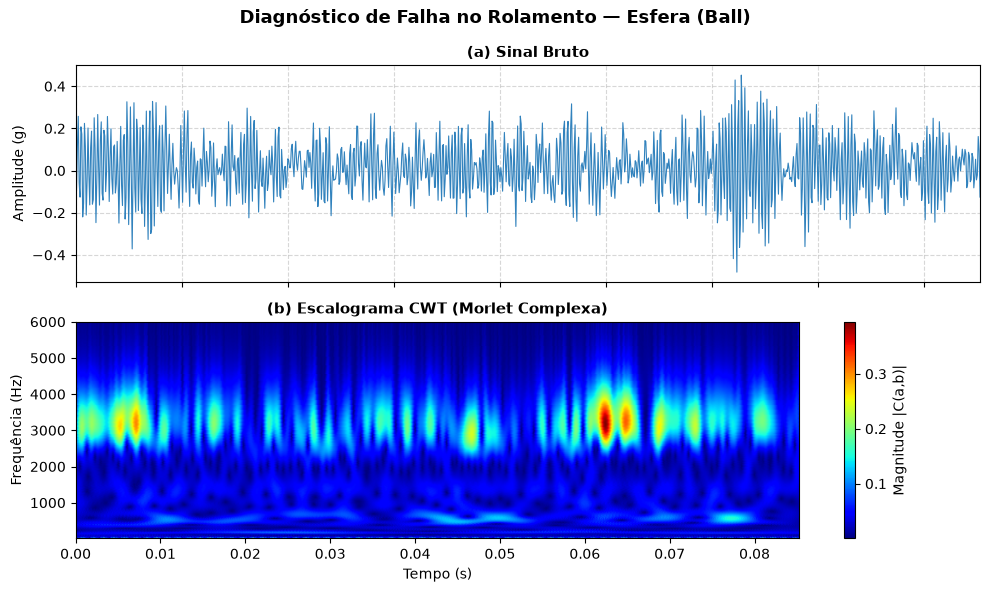

In [4]:
# Chama o módulo de visualização pronto do src/visualization.py
plot_monograph_figure(
    janela_sinal,
    title='Diagnóstico de Falha no Rolamento — Esfera (Ball)'
)

## 5. Geração Automatizada do Dataset de Imagens para a CNN

Para processar todas as 4 classes e gerar o dataset completo de imagens $224 \times 224$
dividido em `train`, `val` e `test`, podemos invocar o pipeline do `src/generate_dataset_cwru.py`:

In [5]:
from src.generate_dataset_cwru import process_and_generate_dataset

# Executa o pipeline de geração de escalogramas CWT com divisão estrita por arquivos:
process_and_generate_dataset()

 GERAÇÃO DO DATASET DE ESCALOGRAMAS (CWT -> CNN) — CWRU 
    Divisão Estrita: Leave-One-Load-Out (0HP+1HP -> 2HP -> 3HP) 

[+] Processando classe: 'normal'...
    train: 2 arquivos → ['Normal_0HP_1797rpm', 'Normal_1HP_1772rpm']


    [OK] train: 1419 imagens geradas
      val: 1 arquivos → ['Normal_2HP_1750rpm']


    [OK] val: 944 imagens geradas
     test: 1 arquivos → ['Normal_3HP_1730rpm']


    [OK] test: 947 imagens geradas

[+] Processando classe: 'inner_race'...
    train: 6 arquivos → ['IR007_0HP_1797rpm', 'IR007_1HP_1772rpm', 'IR014_0HP_1797rpm', 'IR014_1HP_1772rpm', 'IR021_0HP_1797rpm', 'IR021_1HP_1772rpm']


    [OK] train: 1417 imagens geradas
      val: 3 arquivos → ['IR007_2HP_1750rpm', 'IR014_2HP_1750rpm', 'IR021_2HP_1750rpm']


...

    [OK] val: 709 imagens geradas
     test: 3 arquivos → ['OR007_3HP_1730rpm', 'OR014_3HP_1730rpm', 'OR021_3HP_1730rpm']


    [OK] test: 712 imagens geradas

[+] Processando classe: 'ball'...
    train: 6 arquivos → ['B007_0HP_1797rpm', 'B007_1HP_1772rpm', 'B014_0HP_1797rpm', 'B014_1HP_1772rpm', 'B021_0HP_1797rpm', 'B021_1HP_1772rpm']


    [OK] train: 1420 imagens geradas
      val: 3 arquivos → ['B007_2HP_1750rpm', 'B014_2HP_1750rpm', 'B021_2HP_1750rpm']


    [OK] val: 710 imagens geradas
     test: 3 arquivos → ['B007_3HP_1730rpm', 'B014_3HP_1730rpm', 'B021_3HP_1730rpm']


    [OK] test: 710 imagens geradas

 Concluído: Total de 11832 imagens salvas em:
 C:\Users\joaov\Desktop\bearing-fault-diagnosis\bearing-fault-diagnosis-cwt-cnn\data\cwru\processed
